In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

In [3]:
movies = pd.read_csv("../data/raw/movies.csv")
ratings = pd.read_csv("../data/raw/ratings.csv")
tags = pd.read_csv("../data/raw/tags.csv")
links = pd.read_csv("../data/raw/links.csv")

print("Tous les datasets sont chargés !")

Tous les datasets sont chargés !


In [5]:
print("MOVIES")
display(movies.head())

print("RATINGS")
display(ratings.head())

print("TAGS")
display(tags.head())

print("LINKS")
display(links.head())

MOVIES


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


RATINGS


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


TAGS


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


LINKS


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [7]:
print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)
print("Tags shape:", tags.shape)
print("Links shape:", links.shape)

Movies shape: (9742, 3)
Ratings shape: (100836, 4)
Tags shape: (3683, 4)
Links shape: (9742, 3)


In [9]:
print("MOVIES COLUMNS:")
print(movies.columns.tolist())

print("\nRATINGS COLUMNS:")
print(ratings.columns.tolist())

print("\nTAGS COLUMNS:")
print(tags.columns.tolist())

print("\nLINKS COLUMNS:")
print(links.columns.tolist())

MOVIES COLUMNS:
['movieId', 'title', 'genres']

RATINGS COLUMNS:
['userId', 'movieId', 'rating', 'timestamp']

TAGS COLUMNS:
['userId', 'movieId', 'tag', 'timestamp']

LINKS COLUMNS:
['movieId', 'imdbId', 'tmdbId']


In [11]:
print("MOVIES INFO")
movies.info()

print("\nRATINGS INFO")
ratings.info()

print("\nTAGS INFO")
tags.info()

print("\nLINKS INFO")
links.info()

MOVIES INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB

RATINGS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

TAGS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   userId     3683 non-null 

In [13]:
print("MOVIES STATISTICS")
display(movies.describe(include="all"))

print("RATINGS STATISTICS")
display(ratings.describe(include="all"))

print("TAGS STATISTICS")
display(tags.describe(include="all"))

print("LINKS STATISTICS")
display(links.describe(include="all"))

MOVIES STATISTICS


,movieId,title,genres
count,9742.000000,9742,9742
unique,NaN,9737,951
top,NaN,Emma (1996),Drama
freq,NaN,2,1053
mean,42200.353623,NaN,NaN
std,52160.494854,NaN,NaN
min,1.000000,NaN,NaN
25%,3248.250000,NaN,NaN
50%,7300.000000,NaN,NaN
75%,76232.000000,NaN,NaN


RATINGS STATISTICS


,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


TAGS STATISTICS


,userId,movieId,tag,timestamp
count,3683.000000,3683.000000,3683,3.683000e+03
unique,NaN,NaN,1589,NaN
top,NaN,NaN,In Netflix queue,NaN
freq,NaN,NaN,131,NaN
mean,431.149335,27252.013576,NaN,1.320032e+09
std,158.472553,43490.558803,NaN,1.721025e+08
min,2.000000,1.000000,NaN,1.137179e+09
25%,424.000000,1262.500000,NaN,1.137521e+09
50%,474.000000,4454.000000,NaN,1.269833e+09
75%,477.000000,39263.000000,NaN,1.498457e+09


LINKS STATISTICS


,movieId,imdbId,tmdbId
count,9742.000000,9.742000e+03,9734.000000
mean,42200.353623,6.771839e+05,55162.123793
std,52160.494854,1.107228e+06,93653.481487
min,1.000000,4.170000e+02,2.000000
25%,3248.250000,9.518075e+04,9665.500000
50%,7300.000000,1.672605e+05,16529.000000
75%,76232.000000,8.055685e+05,44205.750000
max,193609.000000,8.391976e+06,525662.000000


In [15]:
### Initial Dataset Overview

The MovieLens Latest Small dataset contains:

- 9,742 movies.
- 100,836 user ratings.
- 3,683 user-generated tags.
- 9,742 movie external links.

The ratings dataset contains numerical ratings ranging from 0.5 to 5, with an average rating of approximately 3.50.

The `userId` and `movieId` columns already use the required `int64` data type.

The initial inspection also revealed 8 missing values in the `tmdbId` column and 5 fewer unique movie titles than total movie records.

Further investigation is required to identify duplicate records, missing values, and the distribution of movie genres and ratings.

SyntaxError: invalid syntax (1647019425.py, line 3)

In [17]:
print("Missing values in Movies:")
print(movies.isnull().sum())

print("\nMissing values in Ratings:")
print(ratings.isnull().sum())

print("\nMissing values in Tags:")
print(tags.isnull().sum())

print("\nMissing values in Links:")
print(links.isnull().sum())

Missing values in Movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in Ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Missing values in Tags:
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

Missing values in Links:
movieId    0
imdbId     0
tmdbId     8
dtype: int64


In [19]:
print("Movies duplicates:", movies.duplicated().sum())
print("Ratings duplicates:", ratings.duplicated().sum())
print("Tags duplicates:", tags.duplicated().sum())
print("Links duplicates:", links.duplicated().sum())

Movies duplicates: 0
Ratings duplicates: 0
Tags duplicates: 0
Links duplicates: 0


In [21]:
duplicate_titles = movies[
    movies["title"].duplicated(keep=False)
].sort_values("title")

display(duplicate_titles)

,movieId,title,genres
4169,6003,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller
9106,144606,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Romance|Thriller
650,838,Emma (1996),Comedy|Drama|Romance
5601,26958,Emma (1996),Romance
5854,32600,Eros (2004),Drama
9135,147002,Eros (2004),Drama|Romance
2141,2851,Saturn 3 (1980),Adventure|Sci-Fi|Thriller
9468,168358,Saturn 3 (1980),Sci-Fi|Thriller
5931,34048,War of the Worlds (2005),Action|Adventure|Sci-Fi|Thriller
6932,64997,War of the Worlds (2005),Action|Sci-Fi


In [23]:
print("Duplicate movieId in Movies:",
      movies["movieId"].duplicated().sum())

print("Duplicate movieId in Links:",
      links["movieId"].duplicated().sum())

print("Duplicate userId/movieId pairs in Ratings:",
      ratings.duplicated(subset=["userId", "movieId"]).sum())

Duplicate movieId in Movies: 0
Duplicate movieId in Links: 0
Duplicate userId/movieId pairs in Ratings: 0


In [25]:
for name, df in {
    "Movies": movies,
    "Ratings": ratings,
    "Tags": tags,
    "Links": links
}.items():

    print(f"\n{name}")
    print(df.isnull().sum())


Movies
movieId    0
title      0
genres     0
dtype: int64

Ratings
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Tags
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

Links
movieId    0
imdbId     0
tmdbId     8
dtype: int64


In [27]:
print("Nombre d'utilisateurs :", ratings["userId"].nunique())
print("Nombre de films notés :", ratings["movieId"].nunique())

print("\nDistribution des notes :")
print(ratings["rating"].value_counts().sort_index())

print("\nStatistiques des notes :")
print(ratings["rating"].describe())

Nombre d'utilisateurs : 610
Nombre de films notés : 9724

Distribution des notes :
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

Statistiques des notes :
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


In [29]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculer le nombre d'occurrences de chaque note
rating_counts = ratings['rating'].value_counts().sort_index()

print(rating_counts)


rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


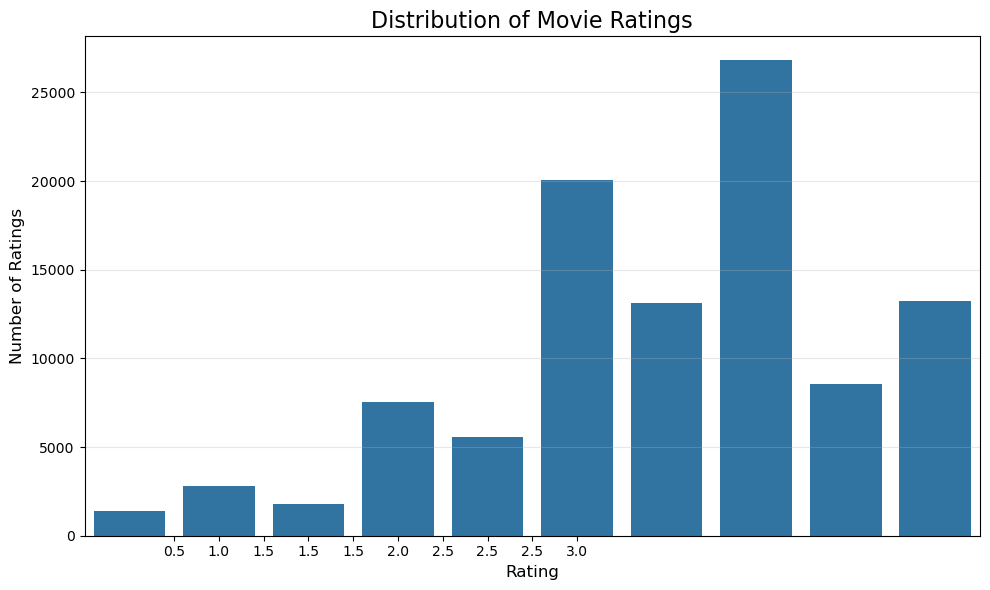

In [31]:

plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title('Distribution of Movie Ratings', fontsize=16)
plt.xlabel('Rating', fontsize=12)
plt.ylabel('Number of Ratings', fontsize=12)

plt.xticks(rating_counts.index)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [33]:

rating_percentages = (
    ratings['rating']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(rating_percentages.round(2))


rating
0.5     1.36
1.0     2.79
1.5     1.78
2.0     7.49
2.5     5.50
3.0    19.88
3.5    13.03
4.0    26.60
4.5     8.48
5.0    13.10
Name: proportion, dtype: float64


In [35]:

positive_ratings = (ratings['rating'] >= 3.5).sum()

positive_percentage = (
    positive_ratings / len(ratings) * 100
)

print(f"Positive ratings: {positive_percentage:.2f}%")


Positive ratings: 61.20%


In [37]:
ratings_per_user = ratings.groupby("userId").size()

print(ratings_per_user.describe())

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64


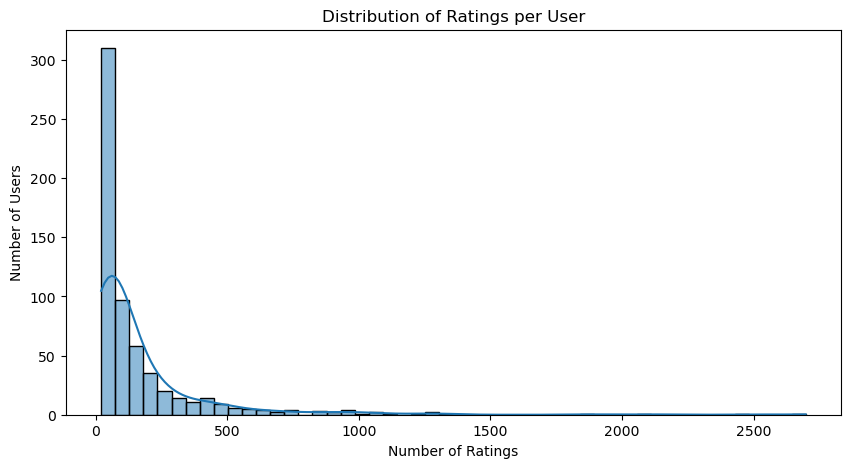

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(ratings_per_user, bins=50, kde=True)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.show()

In [41]:
top_users = ratings_per_user.sort_values(
    ascending=False
).head(10)

print(top_users)

userId
414    2698
599    2478
474    2108
448    1864
274    1346
610    1302
68     1260
380    1218
606    1115
288    1055
dtype: int64


In [43]:
print("Total users:", ratings["userId"].nunique())

print("Average ratings per user:",
      ratings_per_user.mean())

print("Median ratings per user:",
      ratings_per_user.median())

print("Most active user:",
      ratings_per_user.max())

Total users: 610
Average ratings per user: 165.30491803278687
Median ratings per user: 70.5
Most active user: 2698


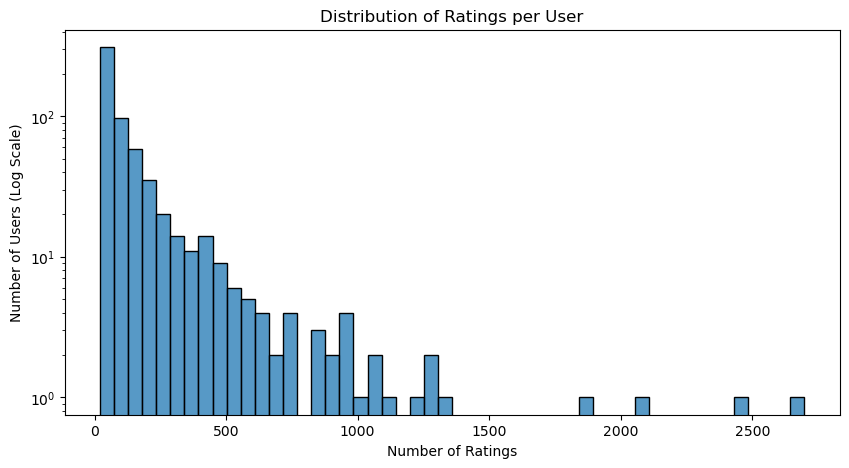

In [45]:
plt.figure(figsize=(10, 5))

sns.histplot(ratings_per_user, bins=50)

plt.yscale("log")

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users (Log Scale)")

plt.show()

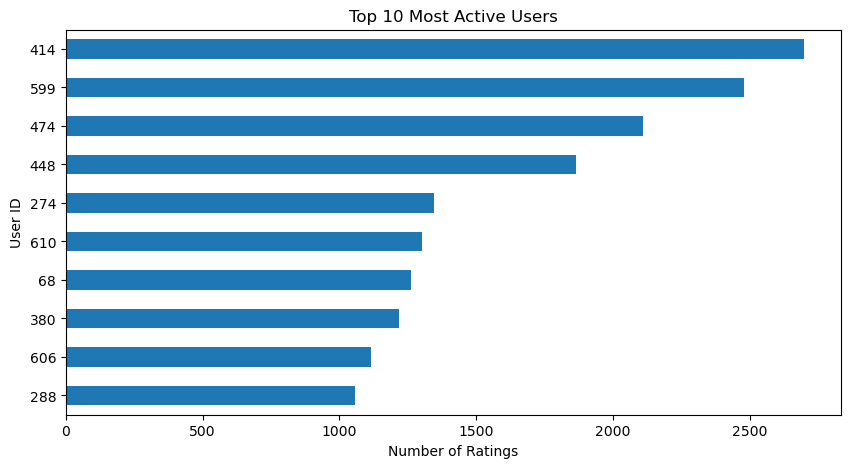

In [47]:
plt.figure(figsize=(10, 5))

top_users.sort_values().plot(kind="barh")

plt.title("Top 10 Most Active Users")
plt.xlabel("Number of Ratings")
plt.ylabel("User ID")

plt.show()

In [49]:
ratings_per_movie = ratings.groupby("movieId").size()

print(ratings_per_movie.describe())

count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64


In [51]:
top_movies = ratings_per_movie.sort_values(
    ascending=False
).head(10)

print(top_movies)

movieId
356     329
318     317
296     307
593     279
2571    278
260     251
480     238
110     237
589     224
527     220
dtype: int64


In [53]:
# Retrieve movie titles
top_movies_df = top_movies.reset_index()

top_movies_df = top_movies_df.merge(
    movies[["movieId", "title"]],
    on="movieId",
    how="left"
)

top_movies_df = top_movies_df[
    ["movieId", "title", 0]
]

top_movies_df.columns = [
    "movieId", "title", "number_of_ratings"
]

print(top_movies_df)

   movieId                                      title  number_of_ratings
0      356                        Forrest Gump (1994)                329
1      318           Shawshank Redemption, The (1994)                317
2      296                        Pulp Fiction (1994)                307
3      593           Silence of the Lambs, The (1991)                279
4     2571                         Matrix, The (1999)                278
5      260  Star Wars: Episode IV - A New Hope (1977)                251
6      480                       Jurassic Park (1993)                238
7      110                          Braveheart (1995)                237
8      589          Terminator 2: Judgment Day (1991)                224
9      527                    Schindler's List (1993)                220


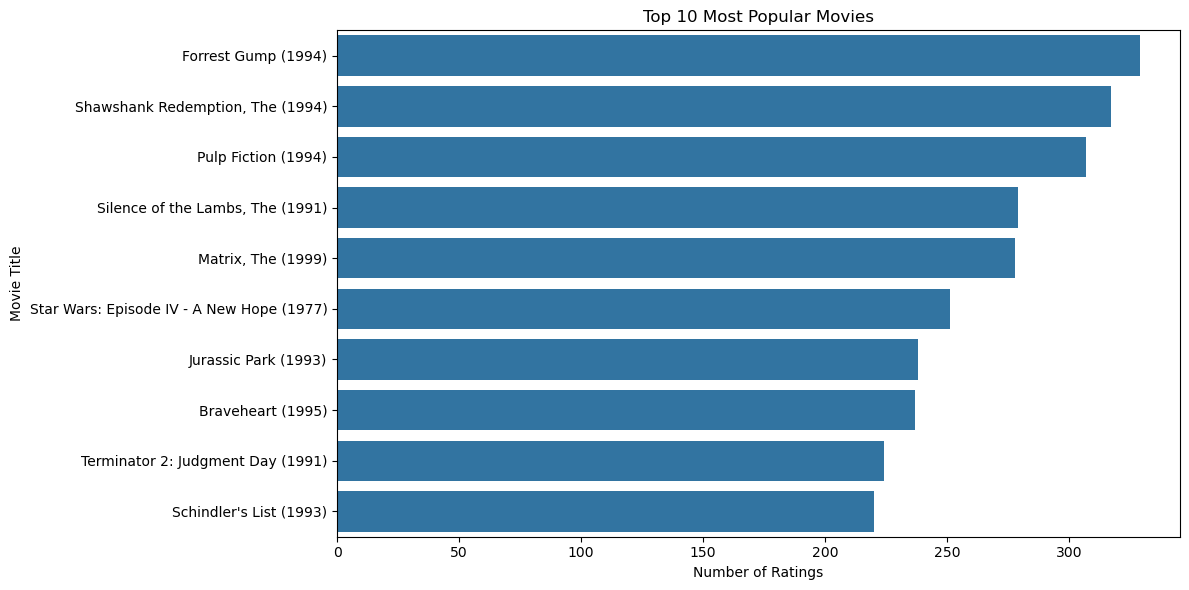

In [55]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_movies_df,
    x="number_of_ratings",
    y="title"
)

plt.title("Top 10 Most Popular Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie Title")

plt.tight_layout()
plt.show()

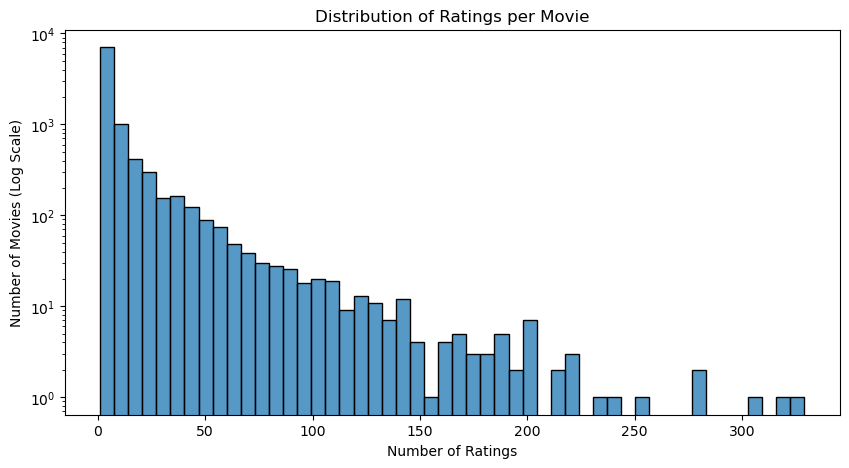

In [57]:
plt.figure(figsize=(10, 5))

sns.histplot(ratings_per_movie, bins=50)

plt.yscale("log")

plt.title("Distribution of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies (Log Scale)")

plt.show()

In [59]:
Movie popularity analysis reveals a highly skewed distribution of ratings. While the average number of ratings per movie is 10.37, the median is only 3. This indicates that most movies receive very few ratings, while a small number of popular movies attract a significantly larger audience. This imbalance is an important consideration when designing the recommendation system.

SyntaxError: invalid syntax (1138654851.py, line 1)

In [61]:
# Split genres into separate rows
movies_genres = movies.copy()

movies_genres["genres"] = movies_genres["genres"].str.split("|")

movies_genres = movies_genres.explode("genres")

movies_genres["genres"] = movies_genres["genres"].str.strip()

print(movies_genres.head(10))

   movieId                    title     genres
0        1         Toy Story (1995)  Adventure
0        1         Toy Story (1995)  Animation
0        1         Toy Story (1995)   Children
0        1         Toy Story (1995)     Comedy
0        1         Toy Story (1995)    Fantasy
1        2           Jumanji (1995)  Adventure
1        2           Jumanji (1995)   Children
1        2           Jumanji (1995)    Fantasy
2        3  Grumpier Old Men (1995)     Comedy
2        3  Grumpier Old Men (1995)    Romance


In [63]:
genre_counts = movies_genres[
    movies_genres["genres"] != "(no genres listed)"
]["genres"].value_counts()

print(genre_counts)

genres
Drama          4361
Comedy         3756
Thriller       1894
Action         1828
Romance        1596
Adventure      1263
Crime          1199
Sci-Fi          980
Horror          978
Fantasy         779
Children        664
Animation       611
Mystery         573
Documentary     440
War             382
Musical         334
Western         167
IMAX            158
Film-Noir        87
Name: count, dtype: int64


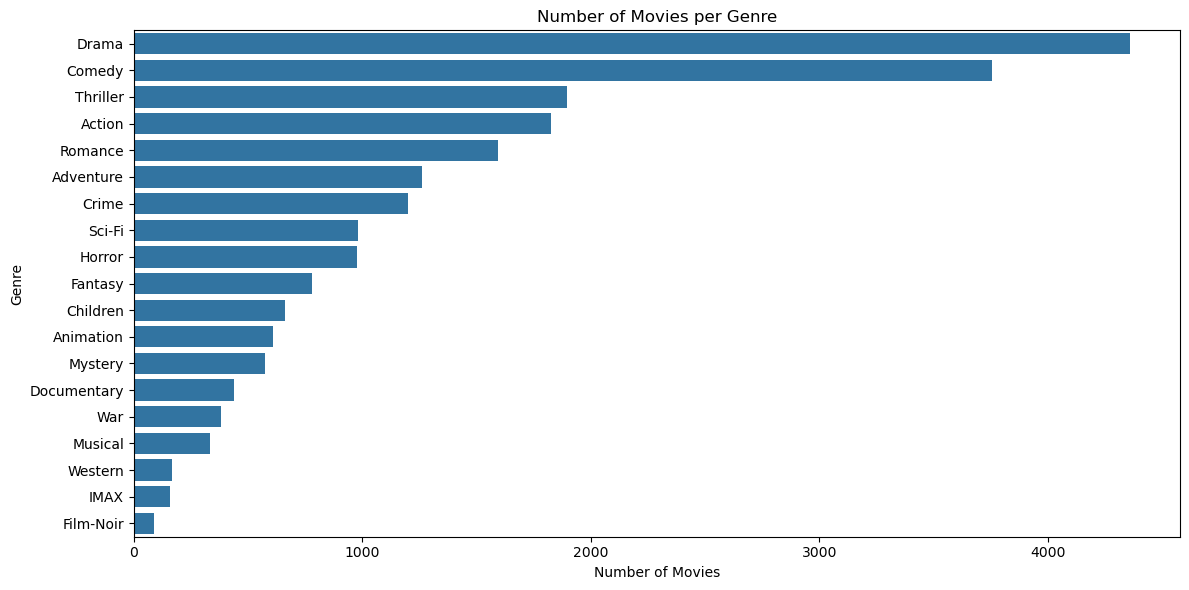

In [65]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Movies per Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [67]:
genre_counts = movies_genres[
    movies_genres["genres"] != "(no genres listed)"
]["genres"].value_counts()

print(genre_counts)

genres
Drama          4361
Comedy         3756
Thriller       1894
Action         1828
Romance        1596
Adventure      1263
Crime          1199
Sci-Fi          980
Horror          978
Fantasy         779
Children        664
Animation       611
Mystery         573
Documentary     440
War             382
Musical         334
Western         167
IMAX            158
Film-Noir        87
Name: count, dtype: int64


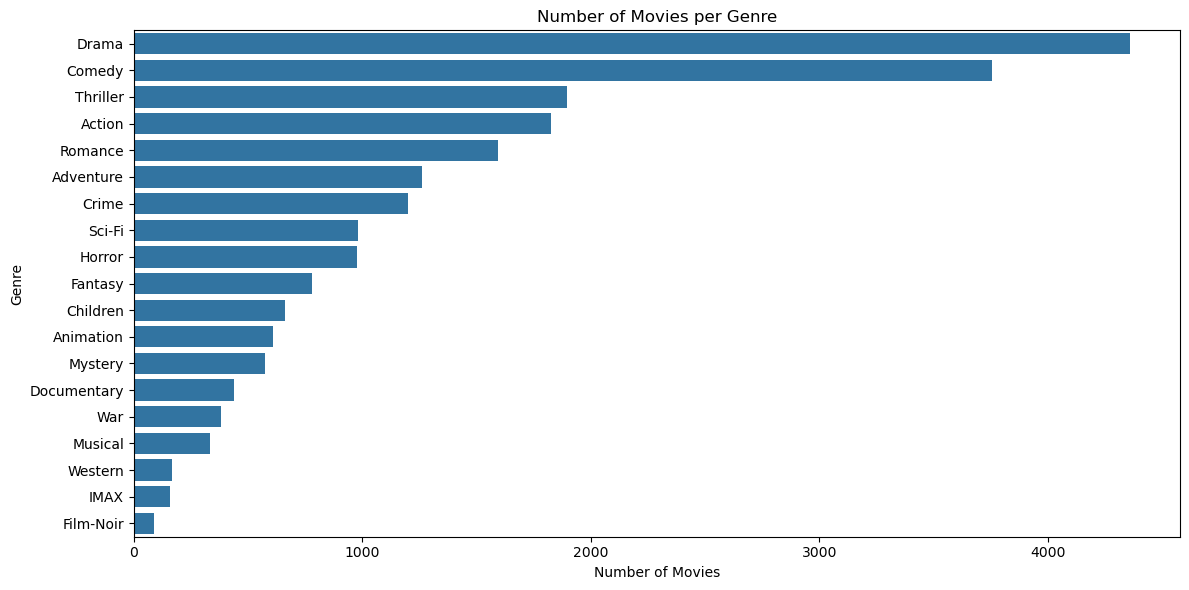

In [69]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Movies per Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [71]:
ratings_movies = ratings.merge(
    movies[["movieId", "genres"]],
    on="movieId",
    how="inner"
)

ratings_movies["genres"] = ratings_movies["genres"].str.split("|")

ratings_movies = ratings_movies.explode("genres")

In [73]:
genre_rating_counts = ratings_movies.groupby(
    "genres"
)["rating"].count().sort_values(ascending=False)

print(genre_rating_counts)

genres
Drama                 41928
Comedy                39053
Action                30635
Thriller              26452
Adventure             24161
Romance               18124
Sci-Fi                17243
Crime                 16681
Fantasy               11834
Children               9208
Mystery                7674
Horror                 7291
Animation              6988
War                    4859
IMAX                   4145
Musical                4138
Western                1930
Documentary            1219
Film-Noir               870
(no genres listed)       47
Name: rating, dtype: int64


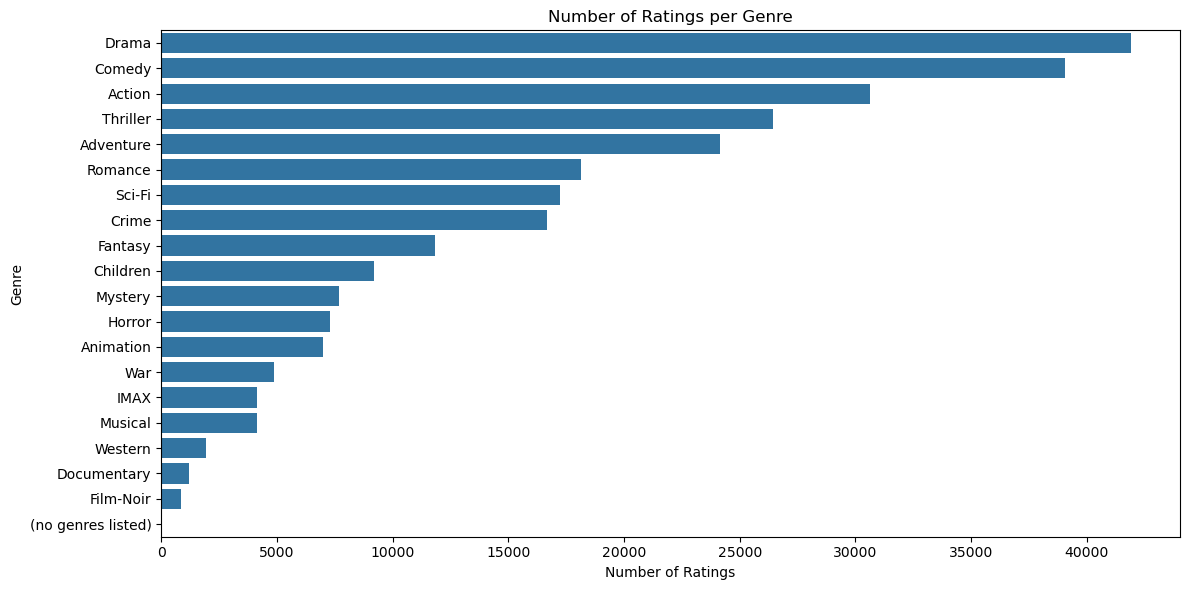

In [75]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_rating_counts.values,
    y=genre_rating_counts.index
)

plt.title("Number of Ratings per Genre")
plt.xlabel("Number of Ratings")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [77]:
genre_avg_ratings = ratings_movies.groupby(
    "genres"
)["rating"].mean().sort_values(ascending=False)

print(genre_avg_ratings)

genres
Film-Noir             3.920115
War                   3.808294
Documentary           3.797785
Crime                 3.658294
Drama                 3.656184
Mystery               3.632460
Animation             3.629937
IMAX                  3.618335
Western               3.583938
Musical               3.563678
Adventure             3.508609
Romance               3.506511
Thriller              3.493706
Fantasy               3.491001
(no genres listed)    3.489362
Sci-Fi                3.455721
Action                3.447984
Children              3.412956
Comedy                3.384721
Horror                3.258195
Name: rating, dtype: float64


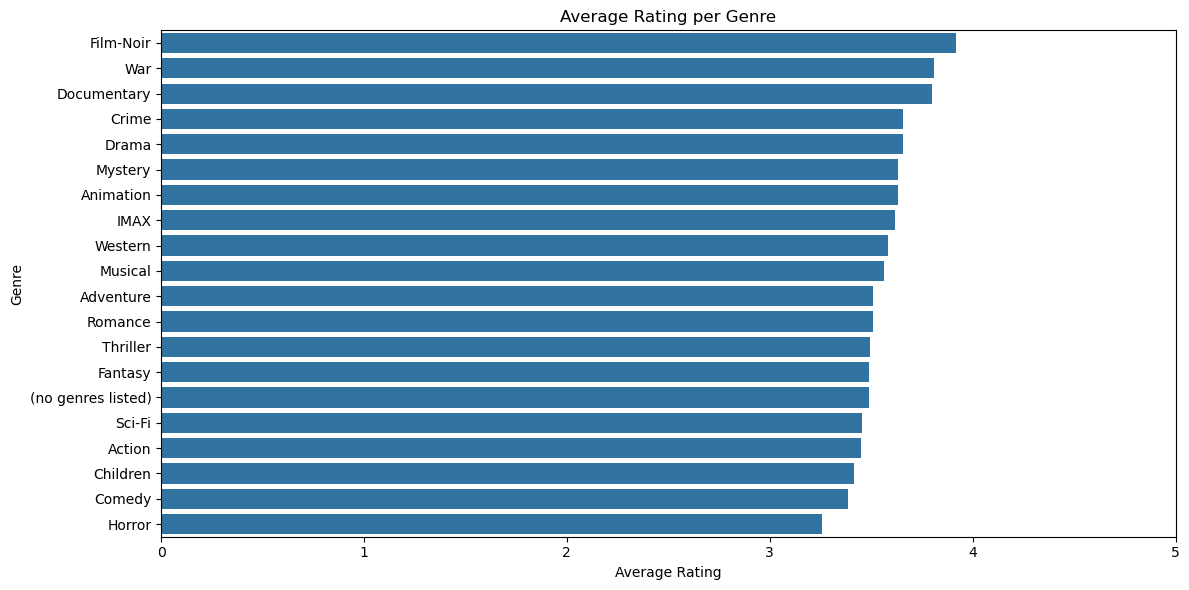

In [79]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_avg_ratings.values,
    y=genre_avg_ratings.index
)

plt.title("Average Rating per Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")

plt.xlim(0, 5)

plt.tight_layout()
plt.show()

In [81]:
ratings["date"] = pd.to_datetime(
    ratings["timestamp"],
    unit="s"
)

ratings["year"] = ratings["date"].dt.year
ratings["month"] = ratings["date"].dt.month

print(ratings[["timestamp", "date", "year", "month"]].head())

   timestamp                date  year  month
0  964982703 2000-07-30 18:45:03  2000      7
1  964981247 2000-07-30 18:20:47  2000      7
2  964982224 2000-07-30 18:37:04  2000      7
3  964983815 2000-07-30 19:03:35  2000      7
4  964982931 2000-07-30 18:48:51  2000      7


In [83]:
print("First rating date:", ratings["date"].min())
print("Last rating date:", ratings["date"].max())

print("Years covered:",
      ratings["year"].nunique())

First rating date: 1996-03-29 18:36:55
Last rating date: 2018-09-24 14:27:30
Years covered: 23


In [85]:
ratings_per_year = ratings.groupby("year").size()

print(ratings_per_year)

year
1996     6040
1997     1916
1998      507
1999     2439
2000    10061
2001     3922
2002     3478
2003     4014
2004     3279
2005     5813
2006     4059
2007     7114
2008     4351
2009     4158
2010     2301
2011     1690
2012     4656
2013     1664
2014     1439
2015     6616
2016     6703
2017     8198
2018     6418
dtype: int64


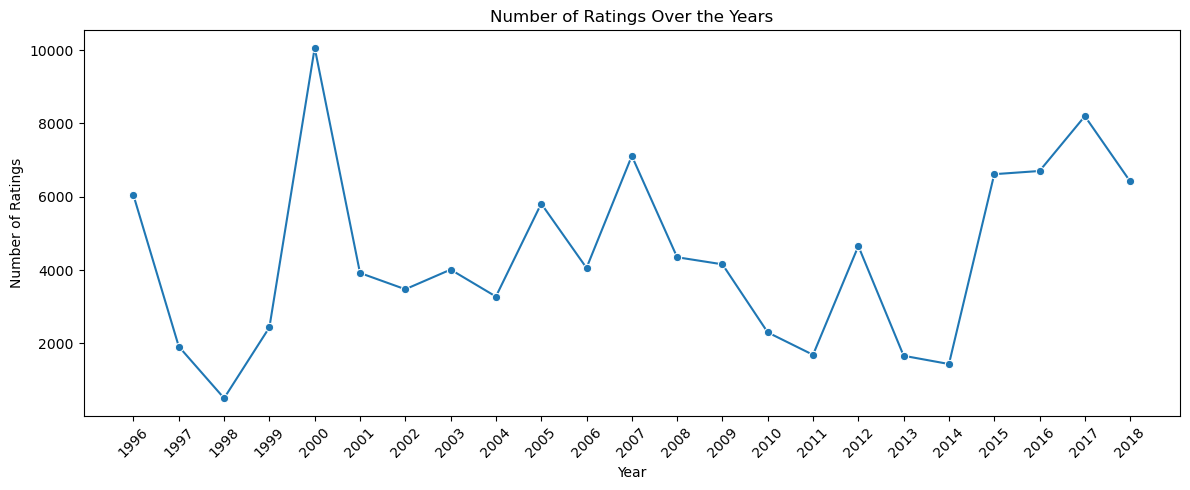

In [87]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=ratings_per_year.index,
    y=ratings_per_year.values,
    marker="o"
)

plt.title("Number of Ratings Over the Years")
plt.xlabel("Year")
plt.ylabel("Number of Ratings")

plt.xticks(ratings_per_year.index, rotation=45)
plt.tight_layout()
plt.show()

In [89]:
avg_rating_per_year = ratings.groupby(
    "year"
)["rating"].mean()

print(avg_rating_per_year)

year
1996    3.535927
1997    3.727557
1998    3.435897
1999    3.772448
2000    3.392506
2001    3.512239
2002    3.606958
2003    3.499377
2004    3.506099
2005    3.431533
2006    3.487928
2007    3.309039
2008    3.656746
2009    3.392496
2010    3.463494
2011    3.784024
2012    3.641323
2013    3.877404
2014    3.510771
2015    3.513830
2016    3.686334
2017    3.348805
2018    3.389062
Name: rating, dtype: float64


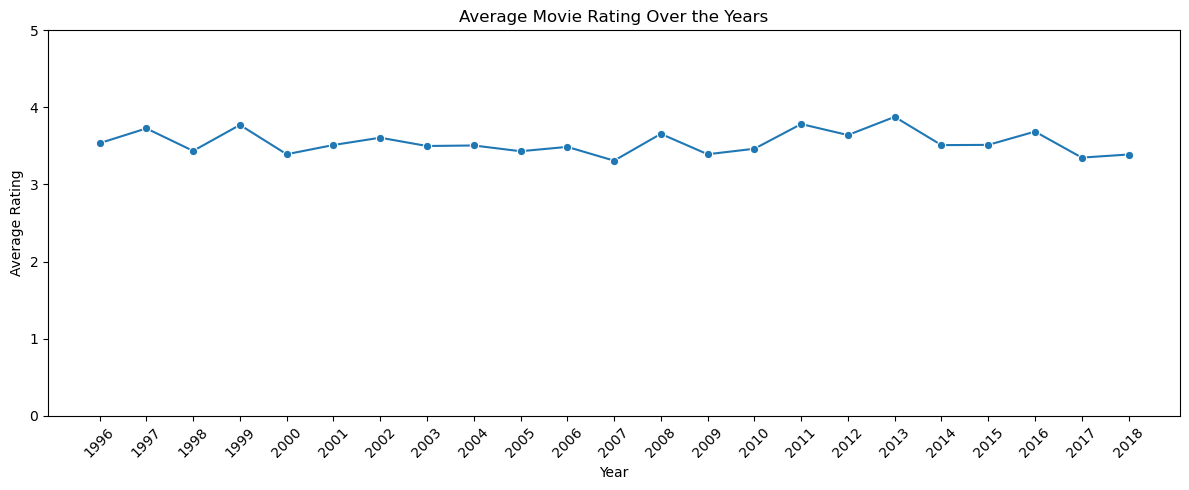

In [91]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=avg_rating_per_year.index,
    y=avg_rating_per_year.values,
    marker="o"
)

plt.title("Average Movie Rating Over the Years")
plt.xlabel("Year")
plt.ylabel("Average Rating")

plt.xticks(avg_rating_per_year.index, rotation=45)
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

In [93]:
ratings_per_month = ratings.groupby(
    "month"
).size()

print(ratings_per_month)

month
1      8684
2      7635
3      8880
4      7727
5     10883
6      8825
7      6950
8      9074
9      8510
10     7148
11     9676
12     6844
dtype: int64


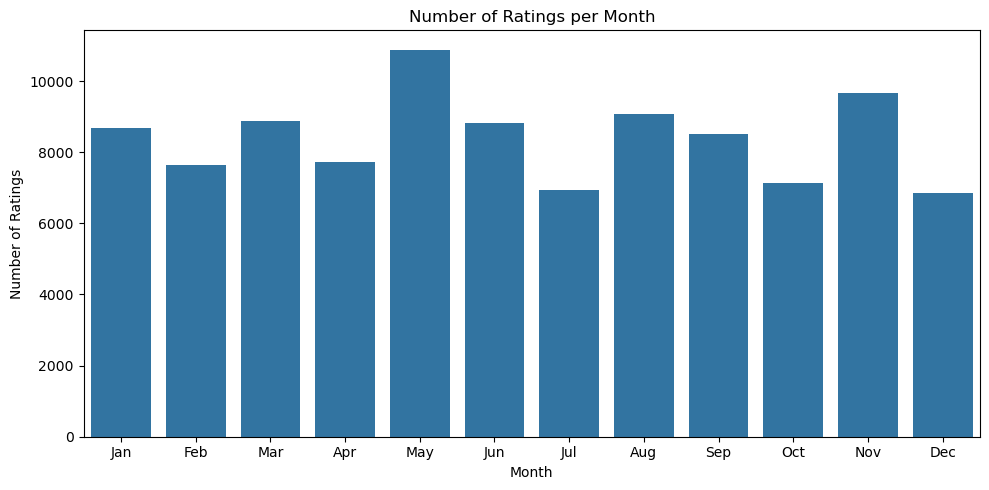

In [95]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=ratings_per_month.index,
    y=ratings_per_month.values
)

plt.title("Number of Ratings per Month")
plt.xlabel("Month")
plt.ylabel("Number of Ratings")

plt.xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
])

plt.tight_layout()
plt.show()

In [97]:
user_movie_matrix = ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Matrix shape:", user_movie_matrix.shape)

Matrix shape: (610, 9724)


In [99]:
total_cells = (
    user_movie_matrix.shape[0] *
    user_movie_matrix.shape[1]
)

existing_ratings = user_movie_matrix.count().sum()

missing_ratings = total_cells - existing_ratings

density = (existing_ratings / total_cells) * 100

sparsity = (missing_ratings / total_cells) * 100

print("Total cells:", total_cells)
print("Existing ratings:", existing_ratings)
print("Missing ratings:", missing_ratings)
print("Density:", density, "%")
print("Sparsity:", sparsity, "%")

Total cells: 5931640
Existing ratings: 100836
Missing ratings: 5830804
Density: 1.6999683055613624 %
Sparsity: 98.30003169443864 %


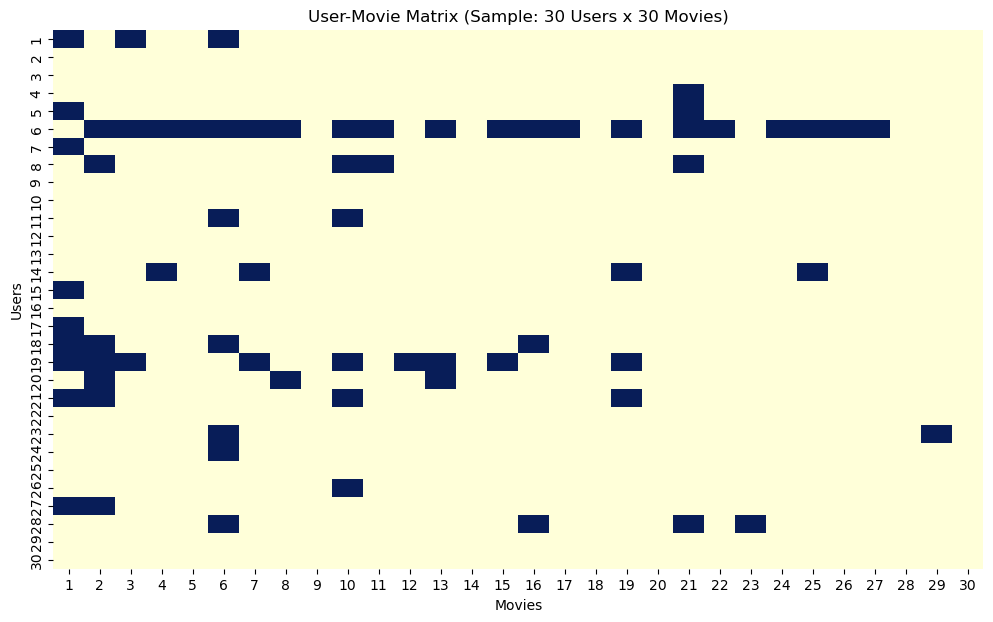

In [101]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    user_movie_matrix.iloc[:30, :30].notna(),
    cmap="YlGnBu",
    cbar=False
)

plt.title("User-Movie Matrix (Sample: 30 Users x 30 Movies)")
plt.xlabel("Movies")
plt.ylabel("Users")

plt.show()

In [103]:
print(tags.head())
print(tags.info())
print("Total tags:", len(tags))
print("Unique tags:", tags["tag"].nunique())

   userId  movieId              tag   timestamp
0       2    60756            funny  1445714994
1       2    60756  Highly quotable  1445714996
2       2    60756     will ferrell  1445714992
3       2    89774     Boxing story  1445715207
4       2    89774              MMA  1445715200
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   userId     3683 non-null   int64 
 1   movieId    3683 non-null   int64 
 2   tag        3683 non-null   object
 3   timestamp  3683 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 115.2+ KB
None
Total tags: 3683
Unique tags: 1589


In [105]:
top_tags = tags["tag"].value_counts().head(20)

print(top_tags)

tag
In Netflix queue      131
atmospheric            36
thought-provoking      24
superhero              24
funny                  23
surreal                23
Disney                 23
religion               22
sci-fi                 21
quirky                 21
dark comedy            21
psychology             21
suspense               20
twist ending           19
visually appealing     19
crime                  19
politics               18
mental illness         16
music                  16
time travel            16
Name: count, dtype: int64


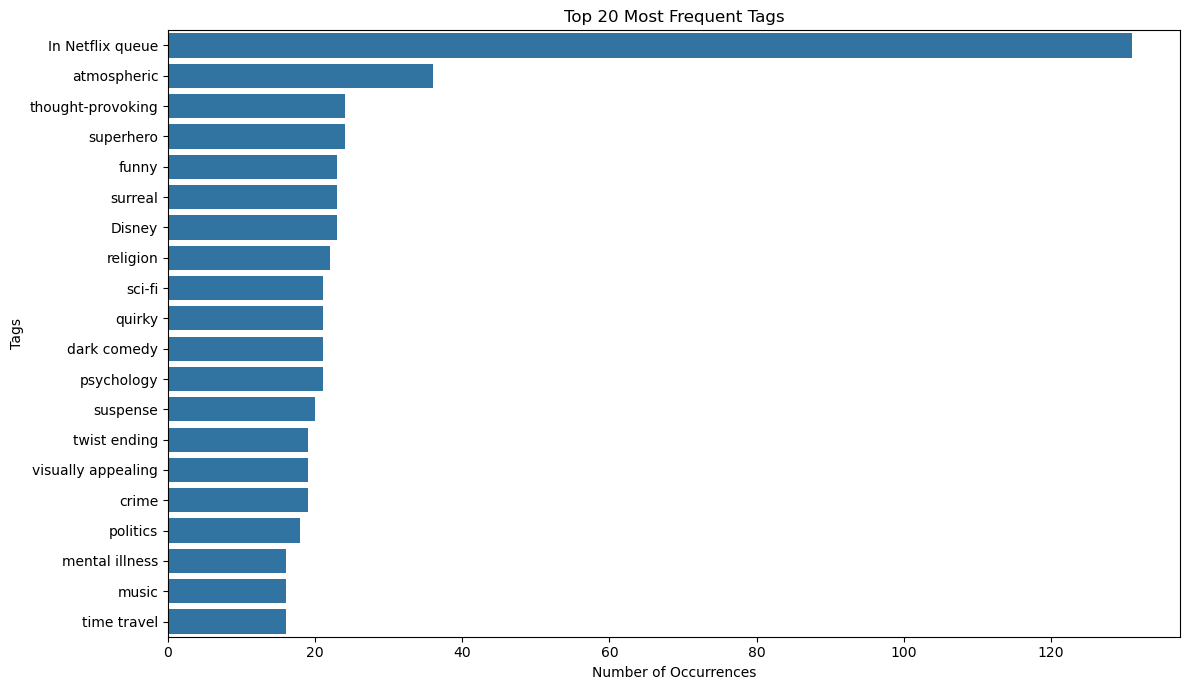

In [107]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_tags.values,
    y=top_tags.index
)

plt.title("Top 20 Most Frequent Tags")
plt.xlabel("Number of Occurrences")
plt.ylabel("Tags")

plt.tight_layout()
plt.show()

In [109]:
tags_per_movie = tags.groupby("movieId").size()

print(tags_per_movie.describe())

print("\nTop 10 movies by number of tags:")
print(tags_per_movie.sort_values(ascending=False).head(10))

count    1572.000000
mean        2.342875
std         5.562342
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       181.000000
dtype: float64

Top 10 movies by number of tags:
movieId
296       181
2959       54
924        41
293        35
7361       34
1732       32
4878       29
79132      26
260        26
135536     19
dtype: int64
